In [0]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

TABLE_NAME = "workspace.default.taco_bueno_clean"

df = spark.table(TABLE_NAME)

# Shared scope: exclude stores identified as incomplete.
base = df.filter(F.col("is_incomplete_store") == 0)

# Paid product lines for product and basket analysis.
# Free items and zero-price combo components are excluded.
products = base.filter(
    (F.col("is_voided") == 0) &
    (F.col("quantity") > 0) &
    (F.col("menu_price") > 0)
)

TICKET_KEYS = ["store_number", "order_date", "check_number"]

display(
    products.select(
        *TICKET_KEYS,
        "menu_item",
        "quantity",
        "menu_price",
        "item_discount",
        "net_item_price",
        "discount_pct"
    ).limit(10)
)

store_number,order_date,check_number,menu_item,quantity,menu_price,item_discount,net_item_price,discount_pct
6866,2026-05-04,99141126459438,Party Burrito,1,1.69,0.0,1.69,0.0
6866,2026-05-04,99141126459438,Beef Muchaco,1,4.49,0.0,4.49,0.0
6866,2026-05-04,99141126459438,Beef Muchaco,1,4.49,0.0,4.49,0.0
5584,2026-05-04,97801096667210,Combo Burrito,1,3.99,0.0,3.99,0.0
5584,2026-05-04,97801096667210,Combo Burrito,1,3.99,0.0,3.99,0.0
5584,2026-05-04,97801096667210,Mexi Dips,1,4.99,0.0,4.99,0.0
5584,2026-05-04,97801096667210,Beef Crispy Taco,1,2.69,0.0,2.69,0.0
5584,2026-05-04,97801096667210,Beef Crispy Taco,1,2.69,0.0,2.69,0.0
5584,2026-05-04,97801096667210,Large Drink Paper,1,3.69,0.0,3.69,0.0
5584,2026-05-04,97801096663089,Beef Burrito,1,4.29,0.0,4.29,0.0


menu_item,product_lines,units,discounted_lines,line_discount_amount,discounted_lines_pct
Beef Crispy Taco,1673990,1683695,667,1348.9200000000008,0.03984492141530117
Beef Muchaco,837136,841028,383,1236.9499999999987,0.045751227996406796
Bean Burrito,1949079,1959939,485,1054.3899999999992,0.02488354756272065
Chicken Quesadilla (w/sauce),350140,350662,195,805.4300000000004,0.05569200891072142
Party Burrito,2636958,2655781,498,760.1800000000019,0.018885397492110226
Beef Wholotta Platter 2025,330635,330880,161,619.0100000000004,0.048694179382098086
Party Taco,1429779,1437499,460,583.5600000000001,0.03217280432850112
Cheesecake 2-Pack,3251,3647,193,482.4300000000003,5.9366348815749
Combo Burrito,420530,421624,194,473.63000000000034,0.046132261669797635
Tamale 3 - Pack,10145,10195,132,430.7299999999996,1.3011335633316905


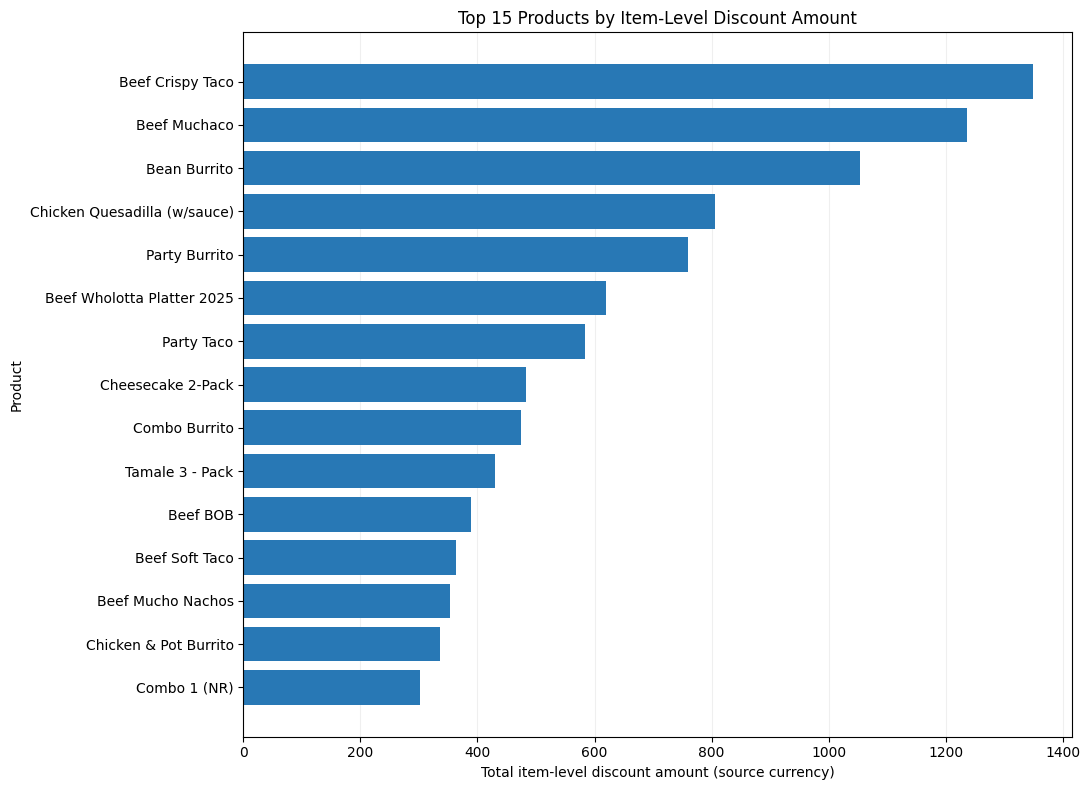

Files saved in: /Workspace/Users/a01663116@tec.mx/Taco Bueno/Week 4/04 Discounts & Baskets/Task 4 Discounts & Baskets/outputs


In [0]:
from pathlib import Path
from pyspark.sql import functions as F
import matplotlib.pyplot as plt


OUTPUT_DIR = Path.cwd() / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


discounts_by_product = (
    products
    .groupBy("menu_item")
    .agg(
        F.count("*").alias("product_lines"),
        F.sum("quantity").alias("units"),
        F.sum(
            F.when(F.col("item_discount") > 0, 1).otherwise(0)
        ).alias("discounted_lines"),
        F.sum(
            F.when(
                F.col("item_discount") > 0,
                F.col("item_discount")
            ).otherwise(0)
        ).alias("line_discount_amount")
    )
    .withColumn(
        "discounted_lines_pct",
        100 * F.col("discounted_lines") / F.col("product_lines")
    )
)

top_discounts = (
    discounts_by_product
    .filter(F.col("line_discount_amount") > 0)
    .orderBy(F.desc("line_discount_amount"), F.asc("menu_item"))
    .limit(15)
    .toPandas()
)

display(top_discounts)

if top_discounts.empty:
    print("No positive item-level discounts found in the selected scope.")
else:
    
    top_discounts.to_csv(
        OUTPUT_DIR / "discounts_by_product.csv",
        index=False
    )

    plot_data = top_discounts.sort_values("line_discount_amount")

    fig, ax = plt.subplots(figsize=(11, 8))
    ax.barh(
        plot_data["menu_item"],
        plot_data["line_discount_amount"],
        color="#2878B5"
    )
    ax.set_title("Top 15 Products by Item-Level Discount Amount")
    ax.set_xlabel("Total item-level discount amount (source currency)")
    ax.set_ylabel("Product")
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

    fig.tight_layout()
    fig.savefig(
        OUTPUT_DIR / "discounts_by_product.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()

    print(f"Files saved in: {OUTPUT_DIR}")

## Finding 1 — Item-level discounts

Beef Crispy Taco has the highest recorded item-level discount amount (1,348.92). Among the 15 products shown, Cheesecake 2-Pack has the highest share of discounted product lines (5.94%), despite its lower sales volume. These metrics describe different dimensions: total discount amount and discount frequency. Order-level discounts are not allocated to products, so this chart does not measure total promotional spending or profitability.

product_a,product_b,tickets_together,basket_support_pct
Party Burrito,Party Taco,263356,4.40819619583093
Bean Burrito,Beef Crispy Taco,198324,3.3196551525006965
Medium Drink Paper,Party Burrito,150964,2.5269176723044877
Bean Burrito,Medium Drink Paper,142188,2.3800202034235345
Party Burrito,Regular Chips and Queso,135986,2.2762077487745294
Party Burrito,Small Drink Paper,129211,2.162804107973657
Bean Burrito,Large Drink Paper,106536,1.783257605367047
Bean Burrito,Regular Chips and Queso,106276,1.7789055837274563
Bean Burrito,Small Drink Paper,99686,1.6685985737086004
Large Drink Paper,Party Burrito,99254,1.6613675223689728


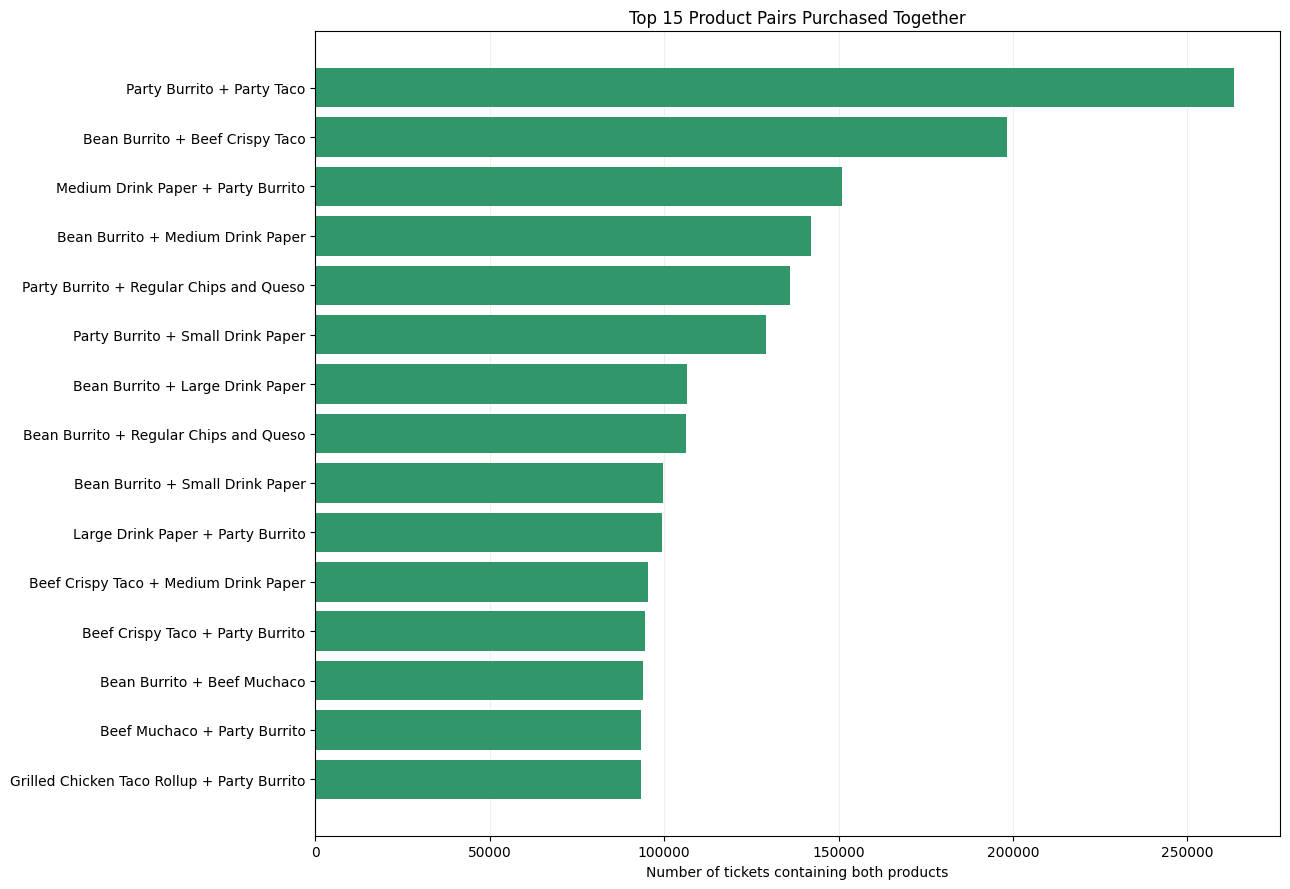

Eligible baskets: 5,974,235
Files saved in: /Workspace/Users/a01663116@tec.mx/Taco Bueno/Week 4/04 Discounts & Baskets/Task 4 Discounts & Baskets/outputs


In [0]:
basket_items = (
    products
    .filter(
        F.col("menu_item").isNotNull() &
        (~F.col("menu_item").isin("Unknown Item", "Modifier (NR)"))
    )
    .select(*TICKET_KEYS, "menu_item")
    .distinct()
)

basket_count = basket_items.select(*TICKET_KEYS).distinct().count()


left_items = basket_items.withColumnRenamed("menu_item", "product_a")
right_items = basket_items.withColumnRenamed("menu_item", "product_b")

pair_counts = (
    left_items
    .join(right_items, TICKET_KEYS, "inner")
    .filter(F.col("product_a") < F.col("product_b"))
    .groupBy("product_a", "product_b")
    .agg(F.count("*").alias("tickets_together"))
    .withColumn(
        "basket_support_pct",
        100 * F.col("tickets_together") / F.lit(basket_count)
    )
)

top_pairs = (
    pair_counts
    .orderBy(
        F.desc("tickets_together"),
        F.asc("product_a"),
        F.asc("product_b")
    )
    .limit(15)
    .toPandas()
)

display(top_pairs)

if top_pairs.empty:
    print("No product pairs found in the selected scope.")
else:
    top_pairs.to_csv(
        OUTPUT_DIR / "basket_composition.csv",
        index=False
    )

    plot_data = top_pairs.sort_values("tickets_together").copy()
    plot_data["pair"] = (
        plot_data["product_a"] + " + " + plot_data["product_b"]
    )

    fig, ax = plt.subplots(figsize=(13, 9))
    ax.barh(
        plot_data["pair"],
        plot_data["tickets_together"],
        color="#31976B"
    )
    ax.set_title("Top 15 Product Pairs Purchased Together")
    ax.set_xlabel("Number of tickets containing both products")
    ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

    fig.tight_layout()
    fig.savefig(
        OUTPUT_DIR / "basket_composition.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()

    print(f"Eligible baskets: {basket_count:,}")
    print(f"Files saved in: {OUTPUT_DIR}")

## Finding 2 — Basket composition

Party Burrito and Party Taco are the most frequent product pair, appearing together in 263,356 tickets (4.41% of eligible baskets). Bean Burrito and Beef Crispy Taco rank second with 198,324 tickets (3.32%). These combinations are candidates for further bundle analysis. However, frequent co-purchase may reflect product popularity; it does not establish incremental demand or profitability. Zero-price components are excluded.

discount_group,tickets,mean_net_ticket,approx_median_net_ticket,total_net_amount
With discount,430050,9.793648436228683,8.15,4211758.510000145
Without discount,5518674,13.77954865971325,11.36,7.604483692009436E7


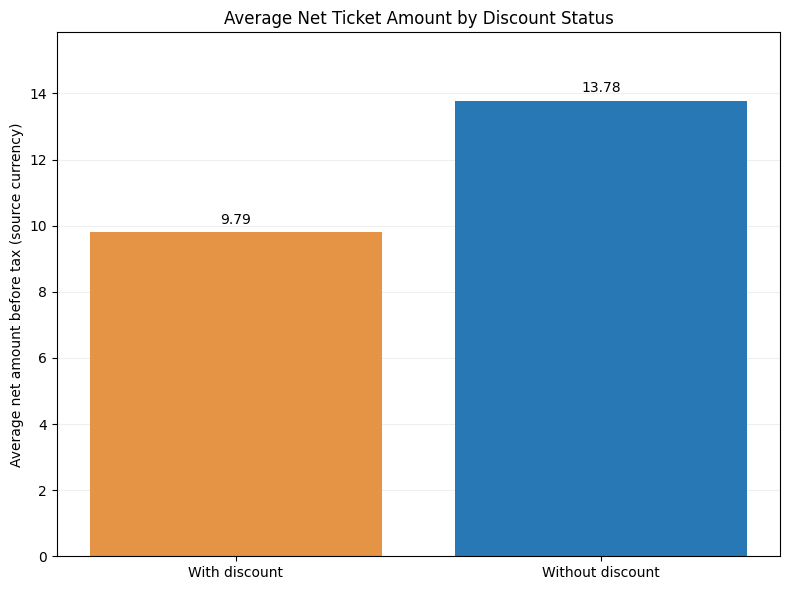

Files saved in: /Workspace/Users/a01663116@tec.mx/Taco Bueno/Week 4/04 Discounts & Baskets/Task 4 Discounts & Baskets/outputs


In [0]:

ticket_data = (
    base
    .filter(F.col("net_total_status") == "reconciled")
    .groupBy(*TICKET_KEYS)
    .agg(
        F.max("net_total").alias("net_ticket_amount"),
        F.max("has_discount").alias("has_discount")
    )
    .withColumn(
        "discount_group",
        F.when(
            F.col("has_discount") == 1,
            "With discount"
        ).otherwise("Without discount")
    )
)

comparison = (
    ticket_data
    .groupBy("discount_group")
    .agg(
        F.count("*").alias("tickets"),
        F.avg("net_ticket_amount").alias("mean_net_ticket"),
        F.percentile_approx(
            "net_ticket_amount", 0.5, 10000
        ).alias("approx_median_net_ticket"),
        F.sum("net_ticket_amount").alias("total_net_amount")
    )
    .orderBy("discount_group")
    .toPandas()
)

display(comparison)

comparison.to_csv(
    OUTPUT_DIR / "discount_comparison.csv",
    index=False
)

fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar(
    comparison["discount_group"],
    comparison["mean_net_ticket"],
    color=["#E49444", "#2878B5"][:len(comparison)]
)

ax.bar_label(bars, fmt="%.2f", padding=4)
ax.set_title("Average Net Ticket Amount by Discount Status")
ax.set_xlabel("")
ax.set_ylabel("Average net amount before tax (source currency)")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.margins(y=0.15)

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "discount_comparison.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print(f"Files saved in: {OUTPUT_DIR}")

## Finding 3 — Tickets with and without discounts
## 
Among reconciled tickets from eligible stores, discounted tickets have an average net amount before tax of 9.79, compared with 13.78 for tickets without discounts—a difference of approximately 28.9%. Approximate medians are also lower: 8.15 versus 11.36.  
This is a descriptive association, not a causal estimate of promotion effectiveness. Net amounts already reflect discounts, and the groups may differ in product mix, basket size, store, and timing. These results alone cannot establish whether promotions generate incremental sales or improve profitability.